# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Integrantes:**

- Andruszyszyn Emanuel
- Quirós Juan

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

...............................                                          [100%]
31 passed in 2.09s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

,Cantidad
Registros,8200
Textos nulos,11
Textos vacíos (incluye nulos y espacios),18
Duplicados por cliente y texto,200


,Tipo de dato,Nulos
id_mensaje,str,0
fecha_hora,str,0
id_cliente,str,0
canal,str,0
texto,str,11
equipo_derivado,str,0
equipo_final,str,0


,Mensajes,Porcentaje
equipo_final,,
transferencias,2552,31.12
tarjeta,2057,25.09
cuenta_acceso,1648,20.10
prestamos_inversiones,1029,12.55
fraude,914,11.15


,Mensajes
canal,
app_chat,3676
whatsapp,2499
email,1163
formulario_web,862


,Mensajes,Promedio,Mediana,Mínimo,Máximo
equipo_final,,,,,
cuenta_acceso,1648,13.87,13.0,0,46
fraude,914,18.22,17.0,0,50
prestamos_inversiones,1029,12.58,12.0,0,33
tarjeta,2057,14.81,14.0,0,42
transferencias,2552,16.95,17.0,0,41


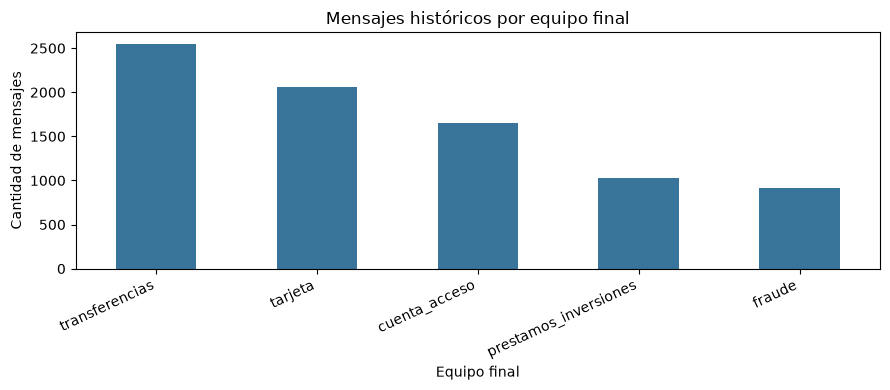

In [3]:
from IPython.display import display

df_original = pd.read_csv("datos/mensajes_historicos.csv")
cantidad_palabras_original = df_original["texto"].fillna("").str.split().str.len()
mensajes_vacios = df_original["texto"].fillna("").str.strip().eq("")
duplicados = df_original.duplicated(subset=["id_cliente", "texto"], keep="first")

resumen_original = pd.Series({
    "Registros": len(df_original),
    "Textos nulos": df_original["texto"].isna().sum(),
    "Textos vacíos (incluye nulos y espacios)": mensajes_vacios.sum(),
    "Duplicados por cliente y texto": duplicados.sum(),
}, name="Cantidad").to_frame()
display(resumen_original)
display(pd.DataFrame({
    "Tipo de dato": df_original.dtypes.astype(str),
    "Nulos": df_original.isna().sum(),
}))

distribucion_equipos = df_original["equipo_final"].value_counts().to_frame("Mensajes")
distribucion_equipos["Porcentaje"] = 100 * distribucion_equipos["Mensajes"] / len(df_original)
display(distribucion_equipos.round(2))
display(df_original["canal"].value_counts().to_frame("Mensajes"))

palabras_por_clase = (
    df_original.assign(palabras=cantidad_palabras_original)
    .groupby("equipo_final")["palabras"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(columns={"count": "Mensajes", "mean": "Promedio", "median": "Mediana", "min": "Mínimo", "max": "Máximo"})
)
display(palabras_por_clase.round(2))

ax = distribucion_equipos["Mensajes"].plot.bar(figsize=(9, 4), color="#39749b")
ax.set_title("Mensajes históricos por equipo final")
ax.set_xlabel("Equipo final")
ax.set_ylabel("Cantidad de mensajes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Transferencias concentra la mayor cantidad de mensajes y fraude es la clase con menos ejemplos. Hay textos nulos o vacíos y registros repetidos por cliente y texto. Los mensajes de fraude tienen el mayor promedio de palabras; los de préstamos e inversiones, el menor. Las tablas muestran los datos originales, antes de quitar registros.

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

clases = np.sort(df_original["equipo_final"].unique())
y_real_manual = df_original["equipo_final"]
y_derivado_manual = df_original["equipo_derivado"]
es_fraude = y_real_manual.eq("fraude")
fraude_otro_equipo = es_fraude & y_derivado_manual.ne("fraude")
correctos_manuales = y_real_manual.eq(y_derivado_manual)

linea_base = pd.Series({
    "Mensajes originales": len(df_original),
    "Derivaciones correctas": correctos_manuales.sum(),
    "Derivaciones incorrectas": (~correctos_manuales).sum(),
    "Accuracy (%)": 100 * accuracy_score(y_real_manual, y_derivado_manual),
    "Errores (%)": 100 * (~correctos_manuales).mean(),
    "F1 macro": f1_score(y_real_manual, y_derivado_manual, labels=clases, average="macro", zero_division=0),
    "Mensajes reales de fraude": es_fraude.sum(),
    "Fraudes enviados a otro equipo": fraude_otro_equipo.sum(),
    "Fraudes enviados a otro equipo (%)": 100 * fraude_otro_equipo.sum() / es_fraude.sum(),
}, name="Resultado").to_frame()
display(linea_base.round(4))

matriz_manual = pd.DataFrame(
    confusion_matrix(y_real_manual, y_derivado_manual, labels=clases),
    index=pd.Index(clases, name="Equipo real"),
    columns=pd.Index(clases, name="Equipo derivado"),
)
matriz_manual_porcentaje = 100 * matriz_manual.div(matriz_manual.sum(axis=1), axis=0)
print("Matriz de confusión: cantidad de mensajes")
display(matriz_manual)
print("Matriz normalizada por fila: porcentaje de cada equipo real")
display(matriz_manual_porcentaje.round(2))

,Resultado
Mensajes originales,8200.0000
Derivaciones correctas,6774.0000
Derivaciones incorrectas,1426.0000
Accuracy (%),82.6098
Errores (%),17.3902
F1 macro,0.8166
Mensajes reales de fraude,914.0000
Fraudes enviados a otro equipo,290.0000
Fraudes enviados a otro equipo (%),31.7287


Matriz de confusión: cantidad de mensajes


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,1347,92,0,97,112
fraude,52,624,0,153,85
prestamos_inversiones,23,0,890,25,91
tarjeta,115,80,0,1722,140
transferencias,77,84,87,113,2191


Matriz normalizada por fila: porcentaje de cada equipo real


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,81.74,5.58,0.00,5.89,6.80
fraude,5.69,68.27,0.00,16.74,9.30
prestamos_inversiones,2.24,0.00,86.49,2.43,8.84
tarjeta,5.59,3.89,0.00,83.71,6.81
transferencias,3.02,3.29,3.41,4.43,85.85


La mesa de entrada acierta el 82,61% de las derivaciones y se equivoca en el 17,39%. De los 914 fraudes reales, 290 llegan a otro equipo (31,73%). Esta es la línea base manual: todavía no evaluamos un modelo sobre el histórico. Tiene sentido comparar una clasificación automática si permite reducir estos errores, especialmente los de fraude.

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [5]:
df_sin_duplicados = df_original.drop_duplicates(subset=["id_cliente", "texto"], keep="first").copy()
duplicados_restantes = df_sin_duplicados.duplicated(subset=["id_cliente", "texto"]).sum()

display(pd.Series({
    "Registros originales": len(df_original),
    "Duplicados eliminados": len(df_original) - len(df_sin_duplicados),
    "Registros restantes": len(df_sin_duplicados),
    "Duplicados restantes por cliente y texto": duplicados_restantes,
}, name="Cantidad").to_frame())
assert duplicados_restantes == 0

,Cantidad
Registros originales,8200
Duplicados eliminados,200
Registros restantes,8000
Duplicados restantes por cliente y texto,0


Quitamos 200 duplicados y quedaron 8.000 mensajes, conservando la primera aparición. Lo hacemos antes de separar entrenamiento y prueba para evitar que un registro repetido aparezca en ambos conjuntos y mejore artificialmente la evaluación. Trabajamos sobre una copia; no cambiamos el CSV ni sus etiquetas.

## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [6]:
import subprocess
import sys

pruebas_limpieza = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_limpieza.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_limpieza.stdout.strip())

# Ejemplos preparados para mostrar las reglas, sin tomar mensajes de clientes.
ejemplos_limpieza = [
    "¡NO PUEDO ENTRAR A MI CUENTA! 😡",
    "Me cobraron $ 15.000 dos veces.",
    "Transferí Gs. 8.350,50 y pagué USD20.",
    "Escribí a ayuda@example.com y entré a https://example.com/ayuda.",
    "La operación 123456 sigue pendiente.\nNecesito   ayuda.",
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Texto original (inventado)": ejemplos_limpieza,
        "Texto limpio": [limpiar_texto(texto) for texto in ejemplos_limpieza],
    }))

...............                                                          [100%]
15 passed in 0.02s


,Texto original (inventado),Texto limpio
0,¡NO PUEDO ENTRAR A MI CUENTA! 😡,no puedo entrar a mi cuenta
1,Me cobraron $ 15.000 dos veces.,me cobraron _monto_ dos veces
2,"Transferí Gs. 8.350,50 y pagué USD20.",transferi _monto_ y pague _monto_
3,Escribí a ayuda@example.com y entré a https://example.com/ayuda.,escribi a _email_ y entre a _url_
4,La operación 123456 sigue pendiente.\nNecesito ayuda.,la operacion _num_ sigue pendiente necesito ayuda


Los cinco ejemplos son inventados. La limpieza unifica mayúsculas y tildes, reemplaza URL, correos, montos y números por tokens y compacta espacios. Los guiones bajos de esos tokens se conservan. No quitamos palabras comunes ni agregamos otras transformaciones.

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [7]:
df_preparado = df_sin_duplicados.copy()
df_preparado["texto_limpio"] = df_preparado["texto"].map(limpiar_texto)
df_preparado["cantidad_palabras_limpias"] = df_preparado["texto_limpio"].str.split().str.len()
mascara_revision = df_preparado["cantidad_palabras_limpias"].lt(2)
mascara_entrenamiento = ~mascara_revision

# Se conservan los índices y los identificadores en memoria para ubicar cada registro.
df_revision = df_preparado.loc[mascara_revision].copy()
df_entrenamiento = df_preparado.loc[mascara_entrenamiento].copy()

display(pd.Series({
    "Mensajes sin duplicados": len(df_preparado),
    "Mensajes con texto_limpio calculado": df_preparado["texto_limpio"].notna().sum(),
    "Textos limpios no vacíos": df_preparado["texto_limpio"].ne("").sum(),
    "Mensajes con menos de dos palabras (revisión)": mascara_revision.sum(),
    "Mensajes aptos para entrenamiento": mascara_entrenamiento.sum(),
}, name="Cantidad").to_frame())
display(df_revision["equipo_final"].value_counts().reindex(clases, fill_value=0).to_frame("Mensajes cortos"))

tipo_contenido_corto = np.select(
    [
        df_revision["texto_limpio"].eq(""),
        df_revision["texto_limpio"].eq("_num_"),
        df_revision["texto_limpio"].eq("_monto_"),
        df_revision["texto_limpio"].eq("_url_"),
        df_revision["texto_limpio"].eq("_email_"),
    ],
    ["Vacío después de limpiar", "Sólo número", "Sólo monto", "Sólo URL", "Sólo correo"],
    default="Una palabra",
)
display(pd.Series(tipo_contenido_corto, name="Contenido").value_counts().to_frame("Mensajes"))
assert len(df_entrenamiento) + len(df_revision) == len(df_preparado)
assert df_entrenamiento["cantidad_palabras_limpias"].ge(2).all()

,Cantidad
Mensajes sin duplicados,8000
Mensajes con texto_limpio calculado,8000
Textos limpios no vacíos,7952
Mensajes con menos de dos palabras (revisión),70
Mensajes aptos para entrenamiento,7930


,Mensajes cortos
equipo_final,
cuenta_acceso,16
fraude,6
prestamos_inversiones,14
tarjeta,18
transferencias,16


,Mensajes
Contenido,
Vacío después de limpiar,48
Una palabra,22


La limpieza se aplicó a los 8.000 mensajes sin duplicados. Quedaron 7.952 textos no vacíos; 70 mensajes tienen menos de dos palabras y se reservan para revisión humana. De esos 70, 48 quedan vacíos y 22 contienen una sola palabra: no alcanzan para describir el problema con suficiente contexto. Los 7.930 restantes quedan preparados para entrenamiento, sin dividirlos ni entrenar un modelo todavía. Las máscaras y las copias mantienen los índices e identificadores originales, pero sólo mostramos agregados.

## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

pruebas_naive_bayes = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_naive_bayes.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_naive_bayes.stdout.strip())

# Demostración con mensajes inventados; no se entrena con el histórico de Cauce.
textos_demo = [
    "no puedo ingresar a mi cuenta",
    "necesito recuperar la clave de mi cuenta",
    "me rechazaron la tarjeta",
    "no puedo activar mi tarjeta",
    "no reconozco esta transferencia",
    "hicieron una transferencia que no reconozco",
]
etiquetas_demo = ["cuenta_acceso", "cuenta_acceso", "tarjeta", "tarjeta", "fraude", "fraude"]
vectorizador_demo = CountVectorizer()
X_demo = vectorizador_demo.fit_transform([limpiar_texto(texto) for texto in textos_demo])
modelo_demo = NaiveBayesMultinomial(alpha=1).fit(X_demo, etiquetas_demo)

consultas_demo = [
    "no puedo ingresar a mi cuenta",
    "me rechazaron la tarjeta",
    "no reconozco esta transferencia",
]
X_consultas_demo = vectorizador_demo.transform([limpiar_texto(texto) for texto in consultas_demo])
probabilidades_demo = modelo_demo.predict_proba(X_consultas_demo)
predicciones_demo = modelo_demo.predict(X_consultas_demo)
resultado_demo = pd.DataFrame({"Mensaje inventado": consultas_demo, "Clase predicha": predicciones_demo})
for indice, clase in enumerate(modelo_demo.classes_):
    resultado_demo[f"P({clase})"] = probabilidades_demo[:, indice]
display(resultado_demo.round(4))
np.testing.assert_allclose(probabilidades_demo.sum(axis=1), 1.0)

............                                                             [100%]
12 passed in 2.05s


,Mensaje inventado,Clase predicha,P(cuenta_acceso),P(fraude),P(tarjeta)
0,no puedo ingresar a mi cuenta,cuenta_acceso,0.8069,0.0464,0.1467
1,me rechazaron la tarjeta,tarjeta,0.0514,0.0333,0.9153
2,no reconozco esta transferencia,fraude,0.0267,0.9337,0.0396


Naive Bayes suma conteos de términos por clase, aplica suavizado y combina logaritmos para evitar underflow. `log_suma_exp` normaliza los puntajes para obtener probabilidades; la clase con la mayor probabilidad es la predicción. Las pruebas verifican el cálculo manual, la equivalencia numérica con scikit-learn, las matrices dispersas y la compatibilidad con Pipeline y GridSearchCV. La tabla usa un conjunto didáctico pequeño: muestra que el código funciona, pero sus probabilidades no son una evaluación del caso Cauce. El análisis de términos del histórico queda para el paso 9.

**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [9]:
from sklearn.model_selection import train_test_split

textos_entrenamiento, textos_prueba, etiquetas_entrenamiento, etiquetas_prueba = train_test_split(
    df_entrenamiento["texto_limpio"], df_entrenamiento["equipo_final"],
    test_size=0.20, random_state=SEMILLA, stratify=df_entrenamiento["equipo_final"],
)
assert SEMILLA == 42
assert textos_entrenamiento.index.intersection(textos_prueba.index).empty
assert textos_entrenamiento.index.intersection(df_revision.index).empty
assert textos_prueba.index.intersection(df_revision.index).empty
assert textos_entrenamiento.str.split().str.len().ge(2).all()
assert textos_prueba.str.split().str.len().ge(2).all()
assert textos_entrenamiento.index.equals(etiquetas_entrenamiento.index)
assert textos_prueba.index.equals(etiquetas_prueba.index)

resumen_division = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Mensajes": [len(textos_entrenamiento), len(textos_prueba)],
})
resumen_division["Porcentaje de los mensajes aptos"] = 100 * resumen_division["Mensajes"] / len(df_entrenamiento)
display(resumen_division)

distribucion_division = pd.DataFrame({
    "Entrenamiento": etiquetas_entrenamiento.value_counts(),
    "Prueba": etiquetas_prueba.value_counts(),
}).reindex(clases)
distribucion_division["Entrenamiento (%)"] = 100 * distribucion_division["Entrenamiento"] / len(etiquetas_entrenamiento)
distribucion_division["Prueba (%)"] = 100 * distribucion_division["Prueba"] / len(etiquetas_prueba)
display(distribucion_division.round(2))

,Conjunto,Mensajes,Porcentaje de los mensajes aptos
0,Entrenamiento,6344,80.0
1,Prueba,1586,20.0


,Entrenamiento,Prueba,Entrenamiento (%),Prueba (%)
equipo_final,,,,
cuenta_acceso,1274,318,20.08,20.05
fraude,707,176,11.14,11.10
prestamos_inversiones,790,198,12.45,12.48
tarjeta,1598,400,25.19,25.22
transferencias,1975,494,31.13,31.15


Separamos los mensajes aptos antes de ajustar el vectorizador. La estratificación mantiene aproximadamente el porcentaje de cada equipo en ambos conjuntos. Conservamos los índices para comprobar que no comparten registros y que los mensajes reservados para revisión humana quedan fuera.

**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [10]:
from sklearn.naive_bayes import MultinomialNB

vectorizador_base = CountVectorizer()
X_entrenamiento_base = vectorizador_base.fit_transform(textos_entrenamiento)
X_prueba_base = vectorizador_base.transform(textos_prueba)
modelo_nb_base = NaiveBayesMultinomial(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)
modelo_nb_referencia = MultinomialNB(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)

np.testing.assert_array_equal(modelo_nb_base.classes_, modelo_nb_referencia.classes_)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Dato": ["Clases", "Orden de clases", "Términos del vocabulario", "Matriz de entrenamiento", "Matriz de prueba"],
        "Valor": [len(modelo_nb_base.classes_), ", ".join(modelo_nb_base.classes_),
                  len(vectorizador_base.get_feature_names_out()), X_entrenamiento_base.shape, X_prueba_base.shape],
    }))

# Prueba se usa aquí para verificar la implementación, sin medir su desempeño.
predicciones_nb_base = modelo_nb_base.predict(X_prueba_base)
predicciones_nb_referencia = modelo_nb_referencia.predict(X_prueba_base)
coincidencias_nb = predicciones_nb_base == predicciones_nb_referencia
probabilidades_nb_base = modelo_nb_base.predict_proba(X_prueba_base)
probabilidades_nb_referencia = modelo_nb_referencia.predict_proba(X_prueba_base)
np.testing.assert_allclose(probabilidades_nb_base, probabilidades_nb_referencia, rtol=1e-8, atol=1e-10)
assert coincidencias_nb.all()
display(pd.Series({
    "Predicciones comparadas": len(coincidencias_nb),
    "Coincidencias": coincidencias_nb.sum(),
    "Coincidencia (%)": 100 * coincidencias_nb.mean(),
    "Diferencia máxima absoluta entre probabilidades": f"{np.abs(probabilidades_nb_base - probabilidades_nb_referencia).max():.3e}",
}, name="Resultado", dtype=object).to_frame())

,Dato,Valor
0,Clases,5
1,Orden de clases,"cuenta_acceso, fraude, prestamos_inversiones, tarjeta, transferencias"
2,Términos del vocabulario,1399
3,Matriz de entrenamiento,"(6344, 1399)"
4,Matriz de prueba,"(1586, 1399)"


,Resultado
Predicciones comparadas,1586
Coincidencias,1586
Coincidencia (%),100.0
Diferencia máxima absoluta entre probabilidades,1.421e-14


La coincidencia comprueba que ambas implementaciones hacen la misma predicción, no que acierten todas las etiquetas reales. Esta comparación no se usa para elegir parámetros, ajustar umbrales ni decidir el modelo final. El vocabulario se aprendió sólo con entrenamiento y la proximidad de las probabilidades se comprobó con una tolerancia numérica.

**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [11]:
vocabulario_base = vectorizador_base.get_feature_names_out()
terminos_por_clase = terminos_mas_indicativos(modelo_nb_base, vocabulario_base, n=10)
assert set(terminos_por_clase) == set(clases)
assert all(len(terminos) == 10 for terminos in terminos_por_clase.values())
tabla_terminos = pd.DataFrame({
    "Categoría": list(terminos_por_clase),
    "Términos más indicativos": [", ".join(terminos) for terminos in terminos_por_clase.values()],
})
with pd.option_context("display.max_colwidth", None):
    display(tabla_terminos)

,Categoría,Términos más indicativos
0,cuenta_acceso,"actualizar, nuevo, validar, reconoce, contrasena, entrar, modifico, validacion, token, ingresar"
1,fraude,"robaron, diciendo, yo, reconozco, pidiendo, ahora, mios, son, aparecen, nombre"
2,prestamos_inversiones,"preaprobado, las, cuotas, ahorros, invertir, punitorios, invierto, vi, pagos, conviene"
3,tarjeta,"cajero, virtual, entrega, nueva, solo, insertandola, fisica, acerco, correo, contactless"
4,transferencias,"transferir, acredito, limite, qr, corresponsal, transferencia, deposite, programada, equivocada, diario"


Los términos se obtienen del modelo y del vocabulario aprendidos únicamente con entrenamiento. El puntaje compara cada palabra con las otras clases; no es una lista de las palabras más frecuentes.

En cuenta_acceso aparecen términos como contrasena, entrar y validar. En fraude sobresalen robaron, reconozco y mios; expresan desconocimiento de operaciones, aunque palabras como yo o ahora dependen mucho del contexto. Cuotas, invertir y punitorios caracterizan préstamos e inversiones; cajero, contactless y virtual distinguen tarjeta; transferir, acredito y qr ayudan a reconocer transferencias. Una mención a una transferencia puede ser un reclamo operativo o un aviso de fraude: reconocer palabras aisladas no alcanza para interpretar todos los mensajes. También las cuotas pueden relacionarse con distintos productos.

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
particiones_cv = list(validacion.split(textos_entrenamiento, etiquetas_entrenamiento))
assert all(set(ajuste).isdisjoint(evaluacion) for ajuste, evaluacion in particiones_cv)

pipeline_nb = Pipeline([
    ("vec", CountVectorizer()),
    ("nb", NaiveBayesMultinomial()),
])
grilla_nb = {
    "nb__alpha": [0.1, 0.5, 1.0, 2.0],
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2],
}
print("Grilla de Naive Bayes:", grilla_nb)
busqueda_nb = GridSearchCV(
    pipeline_nb, grilla_nb, cv=particiones_cv, scoring="f1_macro",
    n_jobs=1, error_score="raise", refit=True,
)
busqueda_nb.fit(textos_entrenamiento, etiquetas_entrenamiento)
modelo_nb_ajustado = busqueda_nb.best_estimator_
resultados_cv_nb = pd.DataFrame(busqueda_nb.cv_results_)
print("Mejores parámetros:", busqueda_nb.best_params_)
print(f"Mejor F1 macro promedio de validación: {busqueda_nb.best_score_:.6f}")
columnas_nb = ["param_nb__alpha", "param_vec__ngram_range", "param_vec__min_df", "mean_test_score", "std_test_score"]
display(
    resultados_cv_nb.sort_values("mean_test_score", ascending=False, kind="stable")
    .head(5)[columnas_nb]
    .rename(columns={"param_nb__alpha": "alpha", "param_vec__ngram_range": "ngram_range",
                     "param_vec__min_df": "min_df", "mean_test_score": "F1 macro promedio",
                     "std_test_score": "Desvío entre particiones"})
    .round(6)
)

# Se cambia un parámetro por vez, manteniendo los otros en la mejor configuración.
efectos_nb = []
for parametro, valores in grilla_nb.items():
    for valor in valores:
        mascara = resultados_cv_nb[f"param_{parametro}"].map(lambda evaluado: evaluado == valor)
        for otro, mejor_valor in busqueda_nb.best_params_.items():
            if otro != parametro:
                mascara &= resultados_cv_nb[f"param_{otro}"].map(lambda evaluado: evaluado == mejor_valor)
        fila = resultados_cv_nb.loc[mascara].iloc[0]
        efectos_nb.append({"Parámetro": parametro, "Valor": str(valor), "F1 macro promedio": fila["mean_test_score"]})
display(pd.DataFrame(efectos_nb).round(6))

Grilla de Naive Bayes: {'nb__alpha': [0.1, 0.5, 1.0, 2.0], 'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 2]}


Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.935575


,alpha,ngram_range,min_df,F1 macro promedio,Desvío entre particiones
3,0.1,"(1, 2)",2,0.935575,0.006523
1,0.1,"(1, 2)",1,0.935467,0.005661
7,0.5,"(1, 2)",2,0.935093,0.004914
5,0.5,"(1, 2)",1,0.934940,0.004809
9,1.0,"(1, 2)",1,0.934298,0.005455


,Parámetro,Valor,F1 macro promedio
0,nb__alpha,0.1,0.935575
1,nb__alpha,0.5,0.935093
2,nb__alpha,1.0,0.933230
3,nb__alpha,2.0,0.932804
4,vec__ngram_range,"(1, 1)",0.929803
5,vec__ngram_range,"(1, 2)",0.935575
6,vec__min_df,1,0.935467
7,vec__min_df,2,0.935575


Probamos una grilla de 16 combinaciones. `alpha` controla el suavizado; `ngram_range` permite palabras individuales o también pares consecutivos; `min_df` exige que un término aparezca en uno o dos documentos para entrar al vocabulario. La búsqueda usa cinco particiones estratificadas del entrenamiento y F1 macro. La última tabla cambia un parámetro por vez manteniendo los demás en la mejor configuración. El pipeline vuelve a aprender el vocabulario dentro de cada partición. Conservamos el mejor estimador para continuar, sin calcular su rendimiento final en prueba.

La mejor combinación usa alpha=0.1, unigramas y bigramas, y min_df=2. Manteniendo los otros parámetros en esos valores, los bigramas mejoraron el promedio frente a usar sólo palabras individuales. El suavizado bajo obtuvo el mayor promedio de la grilla; al aumentarlo, el promedio fue algo menor. Cambiar min_df de uno a dos documentos produjo una diferencia muy pequeña. Continuamos con la combinación seleccionada, sin asumir que diferencias tan chicas se sostendrán en otros datos.

**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ("vec", TfidfVectorizer()),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute", n_jobs=1)),
])
grilla_knn = {
    "knn__n_neighbors": [3, 5, 9],
    "knn__weights": ["uniform", "distance"],
    "vec__ngram_range": [(1, 1), (1, 2)],
}
print("Grilla de KNN:", grilla_knn)
busqueda_knn = GridSearchCV(
    pipeline_knn, grilla_knn, cv=particiones_cv, scoring="f1_macro",
    n_jobs=1, error_score="raise", refit=True,
)
busqueda_knn.fit(textos_entrenamiento, etiquetas_entrenamiento)
modelo_knn_ajustado = busqueda_knn.best_estimator_
resultados_cv_knn = pd.DataFrame(busqueda_knn.cv_results_)
print("Mejores parámetros:", busqueda_knn.best_params_)
print(f"Mejor F1 macro promedio de validación: {busqueda_knn.best_score_:.6f}")
columnas_knn = ["param_knn__n_neighbors", "param_knn__weights", "param_vec__ngram_range", "mean_test_score", "std_test_score"]
display(
    resultados_cv_knn.sort_values("mean_test_score", ascending=False, kind="stable")
    .head(5)[columnas_knn]
    .rename(columns={"param_knn__n_neighbors": "k", "param_knn__weights": "weights",
                     "param_vec__ngram_range": "ngram_range", "mean_test_score": "F1 macro promedio",
                     "std_test_score": "Desvío entre particiones"})
    .round(6)
)
comparacion_validacion = pd.DataFrame({
    "Modelo": ["Naive Bayes", "KNN"],
    "Mejores parámetros": [busqueda_nb.best_params_, busqueda_knn.best_params_],
    "F1 macro promedio de validación": [busqueda_nb.best_score_, busqueda_knn.best_score_],
})
with pd.option_context("display.max_colwidth", None):
    display(comparacion_validacion.round(6))

Grilla de KNN: {'knn__n_neighbors': [3, 5, 9], 'knn__weights': ['uniform', 'distance'], 'vec__ngram_range': [(1, 1), (1, 2)]}


Mejores parámetros: {'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.928744


,k,weights,ngram_range,F1 macro promedio,Desvío entre particiones
11,9,distance,"(1, 2)",0.928744,0.006269
9,9,uniform,"(1, 2)",0.927402,0.006589
5,5,uniform,"(1, 2)",0.924820,0.006634
7,5,distance,"(1, 2)",0.924284,0.007832
3,3,distance,"(1, 2)",0.922201,0.002688


,Modelo,Mejores parámetros,F1 macro promedio de validación
0,Naive Bayes,"{'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}",0.935575
1,KNN,"{'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.928744


KNN busca los k mensajes más cercanos y combina sus etiquetas. `uniform` asigna el mismo peso a cada vecino; `distance` da más peso a los cercanos. TF-IDF reduce el peso de términos muy extendidos. Usamos coseno para comparar la orientación de los vectores y considerar mensajes de diferente longitud. No es siempre mejor que euclídea: con vectores de norma uno, ambas pueden ordenar los vecinos de la misma manera. Coseno y búsqueda `brute` también responden a la consigna. Las 12 configuraciones usan las mismas cinco particiones y F1 macro que Naive Bayes; los resultados de la tabla corresponden a validación, no a prueba.

La mejor configuración usa nueve vecinos, ponderación por distancia y unigramas con bigramas. La ponderación por distancia mejora frente al voto uniforme con nueve vecinos, pero no sucede lo mismo con cinco: su efecto depende de la configuración. Naive Bayes obtuvo un F1 macro promedio algo mayor que KNN en estas particiones. Esta comparación todavía no decide el modelo final: falta evaluar la derivación y, en particular, los errores relacionados con fraude.

**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,Mensajes
Base de entrenamiento para tiempos,5344
Lote fijo de predicción,1000


,Entrenamiento (%),Mensajes de entrenamiento,Naive Bayes (s),KNN (s)
0,25,1336,0.016656,0.043195
1,50,2672,0.018150,0.061785
2,75,4008,0.017722,0.084454
3,100,5344,0.017360,0.103359


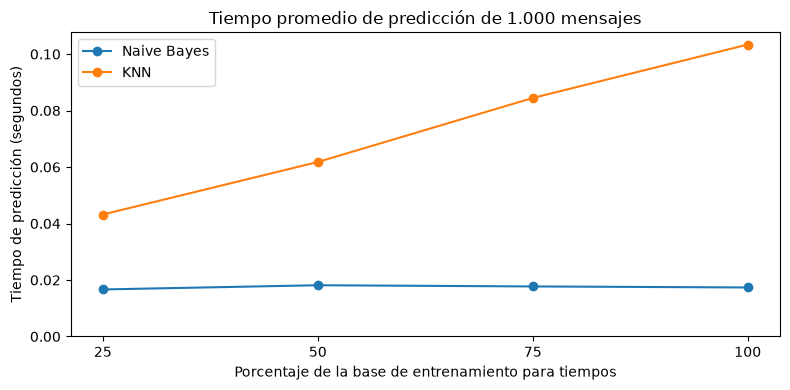

In [14]:
from sklearn.base import clone
from time import perf_counter

# El lote fijo pertenece a entrenamiento y queda fuera del ajuste de este experimento.
textos_base_tiempos, textos_lote_tiempos, etiquetas_base_tiempos, etiquetas_lote_tiempos = train_test_split(
    textos_entrenamiento, etiquetas_entrenamiento,
    test_size=1000, stratify=etiquetas_entrenamiento, random_state=SEMILLA,
)
assert textos_base_tiempos.index.intersection(textos_lote_tiempos.index).empty
assert textos_lote_tiempos.index.intersection(textos_prueba.index).empty
assert len(textos_lote_tiempos) == 1000
display(pd.Series({"Base de entrenamiento para tiempos": len(textos_base_tiempos),
                   "Lote fijo de predicción": len(textos_lote_tiempos)}, name="Mensajes").to_frame())

porcentajes_tiempos = [25, 50, 75, 100]
repeticiones_tiempos = 3
mediciones_tiempos = []
subconjuntos_tiempos = {}
for porcentaje in porcentajes_tiempos:
    cantidad = round(len(textos_base_tiempos) * porcentaje / 100)
    if porcentaje == 100:
        textos_subconjunto, etiquetas_subconjunto = textos_base_tiempos, etiquetas_base_tiempos
    else:
        textos_subconjunto, _, etiquetas_subconjunto, _ = train_test_split(
            textos_base_tiempos, etiquetas_base_tiempos,
            train_size=cantidad, stratify=etiquetas_base_tiempos, random_state=SEMILLA,
        )
    assert textos_subconjunto.index.intersection(textos_lote_tiempos.index).empty
    assert textos_subconjunto.index.intersection(textos_prueba.index).empty
    subconjuntos_tiempos[porcentaje] = textos_subconjunto.index
    modelos_tiempos = {
        "Naive Bayes": clone(modelo_nb_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
        "KNN": clone(modelo_knn_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
    }
    # Una llamada previa evita incluir el costo de la primera predicción en el promedio.
    for modelo in modelos_tiempos.values():
        modelo.predict(textos_lote_tiempos)
    for repeticion in range(repeticiones_tiempos):
        for nombre, modelo in modelos_tiempos.items():
            inicio = perf_counter()
            modelo.predict(textos_lote_tiempos)
            segundos = perf_counter() - inicio
            mediciones_tiempos.append({"Entrenamiento (%)": porcentaje, "Mensajes de entrenamiento": cantidad,
                                      "Modelo": nombre, "Repetición": repeticion + 1, "Segundos": segundos})

mediciones_tiempos = pd.DataFrame(mediciones_tiempos)
tabla_tiempos = (
    mediciones_tiempos.groupby(["Entrenamiento (%)", "Mensajes de entrenamiento", "Modelo"])["Segundos"]
    .mean().unstack("Modelo").reset_index()
    .rename(columns={"Naive Bayes": "Naive Bayes (s)", "KNN": "KNN (s)"})
    [["Entrenamiento (%)", "Mensajes de entrenamiento", "Naive Bayes (s)", "KNN (s)"]]
)
tabla_tiempos.columns.name = None
display(tabla_tiempos.round(6))

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, columna in [("Naive Bayes", "Naive Bayes (s)"), ("KNN", "KNN (s)")]:
    ax.plot(tabla_tiempos["Entrenamiento (%)"], tabla_tiempos[columna], marker="o", label=nombre)
ax.set_title("Tiempo promedio de predicción de 1.000 mensajes")
ax.set_xlabel("Porcentaje de la base de entrenamiento para tiempos")
ax.set_ylabel("Tiempo de predicción (segundos)")
ax.set_xticks(porcentajes_tiempos)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

El 100% corresponde a la base que queda después de reservar el lote de 1.000 mensajes, no a todos los históricos. Ambos modelos usan los mismos subconjuntos estratificados y las configuraciones seleccionadas por validación. Cada promedio incluye tres predicciones completas del pipeline, con transformación del texto y clasificación; excluye entrenamiento y búsqueda de parámetros. Los tiempos pueden variar entre ejecuciones y no representan una medición de producción.

Naive Bayes predijo más rápido en los cuatro tamaños y su tiempo se mantuvo aproximadamente estable. El tiempo de KNN creció al aumentar el entrenamiento porque compara cada consulta con más mensajes almacenados; Naive Bayes usa las probabilidades ya resumidas por clase y término. Para un volumen de 6.500 mensajes diarios, un menor costo de predicción deja más margen de procesamiento, aunque todavía faltan las mediciones y los criterios de un sistema real. Los tiempos favorecen a Naive Bayes en costo, pero por sí solos no justifican la elección final: también hay que considerar la calidad de la clasificación y el tratamiento de fraude.

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [15]:
pruebas_derivacion = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_derivacion.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_derivacion.stdout.strip())
assert np.isnan(evaluar_derivacion([], [])["cobertura"])
assert np.isnan(evaluar_derivacion(["fraude"], [REVISION])["exactitud_automatica"])
assert evaluar_derivacion(["fraude"], [REVISION])["fraude_perdido"] == 0
assert np.isnan(evaluar_derivacion(["tarjeta"], ["tarjeta"])["fraude_perdido"])
print("Sin denominador, el indicador se informa como NaN (no disponible).")

....                                                                     [100%]
4 passed in 0.32s
Sin denominador, el indicador se informa como NaN (no disponible).


La probabilidad de fraude tiene prioridad, aunque otra clase sea más probable. Luego se aplica la confianza y, si no alcanza, se deriva a revisión humana. Los indicadores sin denominador se informan como NaN: no se los reemplaza por una exactitud o un fraude perdido aparentes.

**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [16]:
from sklearn.model_selection import cross_val_predict

modelos_ajustados = {"Naive Bayes": modelo_nb_ajustado, "KNN": modelo_knn_ajustado}
clases_oof = np.unique(etiquetas_entrenamiento)
manual_entrenamiento = df_original.loc[textos_entrenamiento.index, "equipo_derivado"].to_numpy()
y_entrenamiento = etiquetas_entrenamiento.to_numpy()
base_manual_entrenamiento = evaluar_derivacion(y_entrenamiento, manual_entrenamiento)
display(pd.Series(base_manual_entrenamiento, name="Mesa de entrada en entrenamiento").to_frame().round(6))

grilla_fraude = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
grilla_confianza = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98]
probabilidades_oof = {}
busquedas_umbrales = {}
selecciones_umbrales = {}
vecinos_umbrales = {}
for nombre, modelo in modelos_ajustados.items():
    np.testing.assert_array_equal(modelo.classes_, clases_oof)
    for ajuste, fuera_muestra in particiones_cv:
        np.testing.assert_array_equal(np.unique(y_entrenamiento[ajuste]), clases_oof)
    proba_oof = cross_val_predict(
        modelo, textos_entrenamiento, etiquetas_entrenamiento,
        cv=particiones_cv, method="predict_proba", n_jobs=1,
    )
    assert proba_oof.shape == (len(textos_entrenamiento), len(clases_oof))
    assert np.isfinite(proba_oof).all()
    np.testing.assert_allclose(proba_oof.sum(axis=1), 1, atol=1e-10)
    probabilidades_oof[nombre] = proba_oof
    filas_umbrales = []
    for umbral_fraude in grilla_fraude:
        for umbral_confianza in grilla_confianza:
            destinos_oof = derivar(proba_oof, clases_oof, umbral_fraude, umbral_confianza)
            indicadores = evaluar_derivacion(y_entrenamiento, destinos_oof)
            margenes_exactitud, margenes_fraude = [], []
            for _, fuera_muestra in particiones_cv:
                manual_fold = evaluar_derivacion(y_entrenamiento[fuera_muestra], manual_entrenamiento[fuera_muestra])
                modelo_fold = evaluar_derivacion(y_entrenamiento[fuera_muestra], destinos_oof[fuera_muestra])
                margenes_exactitud.append(modelo_fold["exactitud_automatica"] - manual_fold["exactitud_automatica"])
                margenes_fraude.append(manual_fold["fraude_perdido"] - modelo_fold["fraude_perdido"])
            filas_umbrales.append({
                "umbral_fraude": umbral_fraude, "umbral_confianza": umbral_confianza, **indicadores,
                "margen_exactitud_min": min(margenes_exactitud),
                "margen_fraude_min": min(margenes_fraude),
            })
    tabla_busqueda = pd.DataFrame(filas_umbrales)
    tabla_busqueda["mejora_en_cada_fold"] = (
        tabla_busqueda["margen_exactitud_min"].gt(0) & tabla_busqueda["margen_fraude_min"].gt(0)
    )
    tabla_busqueda["estable_en_vecinos"] = False
    # Un candidato interior debe conservar la mejora con sus cuatro vecinos de grilla.
    for indice, fila in tabla_busqueda.iterrows():
        i_fraude = grilla_fraude.index(fila["umbral_fraude"])
        i_confianza = grilla_confianza.index(fila["umbral_confianza"])
        if i_fraude in (0, len(grilla_fraude) - 1) or i_confianza in (0, len(grilla_confianza) - 1):
            continue
        pares = [(fila["umbral_fraude"], fila["umbral_confianza"]),
                 (grilla_fraude[i_fraude - 1], fila["umbral_confianza"]),
                 (grilla_fraude[i_fraude + 1], fila["umbral_confianza"]),
                 (fila["umbral_fraude"], grilla_confianza[i_confianza - 1]),
                 (fila["umbral_fraude"], grilla_confianza[i_confianza + 1])]
        vecinos = tabla_busqueda.loc[[
            (u_f, u_c) in pares for u_f, u_c in zip(tabla_busqueda["umbral_fraude"], tabla_busqueda["umbral_confianza"])
        ]]
        tabla_busqueda.loc[indice, "estable_en_vecinos"] = vecinos["mejora_en_cada_fold"].all()
    candidatos = tabla_busqueda.loc[tabla_busqueda["estable_en_vecinos"]].sort_values(
        ["cobertura", "fraude_perdido", "exactitud_automatica", "umbral_fraude", "umbral_confianza"],
        ascending=[False, True, False, True, True], kind="stable",
    )
    if candidatos.empty:
        raise ValueError(f"{nombre}: no hay un punto estable que mejore la mesa de entrada; revisar sólo OOF.")
    elegido = candidatos.iloc[0].copy()
    selecciones_umbrales[nombre] = elegido
    busquedas_umbrales[nombre] = tabla_busqueda
    print(nombre, "- cinco candidatos estables con mayor cobertura")
    display(candidatos.head(5)[["umbral_fraude", "umbral_confianza", "cobertura", "exactitud_automatica", "fraude_perdido"]].round(6))
    i_f = grilla_fraude.index(elegido["umbral_fraude"])
    i_c = grilla_confianza.index(elegido["umbral_confianza"])
    pares_elegidos = [(elegido["umbral_fraude"], elegido["umbral_confianza"]),
                     (grilla_fraude[i_f - 1], elegido["umbral_confianza"]),
                     (grilla_fraude[i_f + 1], elegido["umbral_confianza"]),
                     (elegido["umbral_fraude"], grilla_confianza[i_c - 1]),
                     (elegido["umbral_fraude"], grilla_confianza[i_c + 1])]
    vecinos_umbrales[nombre] = tabla_busqueda.loc[[
        (u_f, u_c) in pares_elegidos for u_f, u_c in zip(tabla_busqueda["umbral_fraude"], tabla_busqueda["umbral_confianza"])
    ]]
    print("Sensibilidad del punto elegido y sus vecinos; márgenes respecto de la mesa en el peor fold")
    display(vecinos_umbrales[nombre][["umbral_fraude", "umbral_confianza", "cobertura", "exactitud_automatica",
                                      "fraude_perdido", "margen_exactitud_min", "margen_fraude_min"]].round(6))

umbrales_congelados = {
    nombre: (float(fila["umbral_fraude"]), float(fila["umbral_confianza"]))
    for nombre, fila in selecciones_umbrales.items()
}
print("Umbrales provisionales fijados antes de evaluar prueba:", umbrales_congelados)
print("Las proporciones de las tablas van de 0 a 1. Los márgenes son diferencias de proporciones.")
print("Criterios de aceptación pendientes de confirmación.")

,Mesa de entrada en entrenamiento
cobertura,1.000000
exactitud_automatica,0.823613
fraude_perdido,0.316832


Naive Bayes - cinco candidatos estables con mayor cobertura


,umbral_fraude,umbral_confianza,cobertura,exactitud_automatica,fraude_perdido
8,0.10,0.6,0.994798,0.943591,0.069307
15,0.15,0.6,0.994168,0.944189,0.073550
22,0.20,0.6,0.993380,0.945255,0.074965
29,0.25,0.6,0.993222,0.945405,0.077793
36,0.30,0.6,0.993222,0.945247,0.079208


Sensibilidad del punto elegido y sus vecinos; márgenes respecto de la mesa en el peor fold


,umbral_fraude,umbral_confianza,cobertura,exactitud_automatica,fraude_perdido,margen_exactitud_min,margen_fraude_min
1,0.05,0.6,0.995113,0.942658,0.065064,0.099006,0.184397
7,0.10,0.5,0.998108,0.941409,0.070721,0.098359,0.184397
8,0.10,0.6,0.994798,0.943591,0.069307,0.100543,0.184397
9,0.10,0.7,0.991961,0.944859,0.067893,0.100497,0.184397
15,0.15,0.6,0.994168,0.944189,0.073550,0.100543,0.177305


KNN - cinco candidatos estables con mayor cobertura


,umbral_fraude,umbral_confianza,cobertura,exactitud_automatica,fraude_perdido
8,0.10,0.6,0.968317,0.919746,0.038190
15,0.15,0.6,0.953657,0.949091,0.049505
22,0.20,0.6,0.949559,0.954349,0.050919
9,0.10,0.7,0.948770,0.922579,0.035361
29,0.25,0.6,0.940416,0.961783,0.057992


Sensibilidad del punto elegido y sus vecinos; márgenes respecto de la mesa en el peor fold


,umbral_fraude,umbral_confianza,cobertura,exactitud_automatica,fraude_perdido,margen_exactitud_min,margen_fraude_min
1,0.05,0.6,0.972730,0.896451,0.036775,0.050485,0.226950
7,0.10,0.5,0.983607,0.914583,0.041018,0.072535,0.226950
8,0.10,0.6,0.968317,0.919746,0.038190,0.076049,0.226950
9,0.10,0.7,0.948770,0.922579,0.035361,0.078721,0.234043
15,0.15,0.6,0.953657,0.949091,0.049505,0.100888,0.219858


Umbrales provisionales fijados antes de evaluar prueba: {'Naive Bayes': (0.1, 0.6), 'KNN': (0.1, 0.6)}
Las proporciones de las tablas van de 0 a 1. Los márgenes son diferencias de proporciones.
Criterios de aceptación pendientes de confirmación.


No se encontraron los cinco indicadores oficiales, sus metas ni una definición del margen en el notebook, los módulos, el README docente y la explicación de escenarios. Usamos un criterio propio provisional: mejorar exactitud de derivación y fraude perdido respecto de la mesa en cada una de las cinco particiones, mantener esa mejora con los cuatro umbrales vecinos y, entre candidatos estables, maximizar cobertura. En empates se prioriza menor fraude perdido y mayor exactitud. El análisis de sensibilidad aporta un margen empírico, no una garantía estadística ni una meta docente. La grilla tiene 56 pares por modelo y las probabilidades son OOF de entrenamiento. Su reutilización para elegir umbrales puede favorecer esas estimaciones; la evaluación reservada permite contrastarlas. Las decisiones se fijan antes de mirar prueba.

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [17]:
from sklearn.metrics import classification_report

# Los cinco indicadores son una propuesta descriptiva, sin metas oficiales confirmadas.
y_prueba = etiquetas_prueba.to_numpy()
manual_prueba = df_original.loc[textos_prueba.index, "equipo_derivado"].to_numpy()
predicciones_prueba = {}
destinos_prueba = {}
probabilidades_prueba = {}
filas_finales = []
for nombre, modelo in modelos_ajustados.items():
    proba = modelo.predict_proba(textos_prueba)
    predicho = modelo.classes_[proba.argmax(axis=1)]
    destino = derivar(proba, modelo.classes_, *umbrales_congelados[nombre])
    probabilidades_prueba[nombre], predicciones_prueba[nombre], destinos_prueba[nombre] = proba, predicho, destino
    filas_finales.append({"Modelo": nombre,
                         "accuracy": accuracy_score(y_prueba, predicho),
                         "f1_macro": f1_score(y_prueba, predicho, average="macro", zero_division=0),
                         **evaluar_derivacion(y_prueba, destino)})
filas_finales.append({"Modelo": "Mesa de entrada",
                     "accuracy": accuracy_score(y_prueba, manual_prueba),
                     "f1_macro": f1_score(y_prueba, manual_prueba, average="macro", zero_division=0),
                     **evaluar_derivacion(y_prueba, manual_prueba)})
tabla_final = pd.DataFrame(filas_finales).set_index("Modelo")
tabla_final_visible = tabla_final.copy()
for columna in ["accuracy", "cobertura", "exactitud_automatica", "fraude_perdido"]:
    tabla_final_visible[columna] *= 100
tabla_final_visible = tabla_final_visible.rename(columns={
    "accuracy": "Accuracy (%)", "f1_macro": "F1 macro", "cobertura": "Cobertura (%)",
    "exactitud_automatica": "Exactitud automática (%)", "fraude_perdido": "Fraude perdido (%)",
})
print(f"Evaluación final: los mismos {len(y_prueba)} mensajes aptos para los tres métodos.")
display(tabla_final_visible.round(4))
print("En la mesa, cobertura y exactitud automática equivalentes comparan destinos manuales ya realizados.")

# Prioridad declarada: fraude perdido, exactitud automática, cobertura, F1 y costo de predicción.
tabla_eleccion = tabla_final.loc[list(modelos_ajustados)].copy()
tabla_eleccion["tiempo_prediccion"] = [
    float(tabla_tiempos.loc[tabla_tiempos["Entrenamiento (%)"].eq(100), f"{nombre} (s)"].iloc[0])
    for nombre in tabla_eleccion.index
]
nombre_elegido = tabla_eleccion.sort_values(
    ["fraude_perdido", "exactitud_automatica", "cobertura", "f1_macro", "tiempo_prediccion"],
    ascending=[True, False, False, False, True], kind="stable",
).index[0]
modelo_elegido = modelos_ajustados[nombre_elegido]
umbrales_elegidos = umbrales_congelados[nombre_elegido]
destino_elegido_prueba = destinos_prueba[nombre_elegido]
predicho_elegido_prueba = predicciones_prueba[nombre_elegido]
print("Modelo elegido para resolver el ejercicio:", nombre_elegido)
print("Umbrales mantenidos desde OOF:", umbrales_elegidos)
reporte_dict = classification_report(y_prueba, predicho_elegido_prueba, labels=clases, output_dict=True, zero_division=0)
reporte_clasificacion = pd.DataFrame.from_dict({k: v for k, v in reporte_dict.items() if isinstance(v, dict)}, orient="index")
display(reporte_clasificacion.rename(columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1", "support": "Mensajes"}).round(4))
matriz_elegida = pd.DataFrame(
    confusion_matrix(y_prueba, predicho_elegido_prueba, labels=clases),
    index=pd.Index(clases, name="Equipo real"), columns=pd.Index(clases, name="Equipo predicho"),
)
display(matriz_elegida)
display((100 * matriz_elegida.div(matriz_elegida.sum(axis=1), axis=0)).round(2))
mascara_error_automatico = (destino_elegido_prueba != REVISION) & (destino_elegido_prueba != y_prueba)
indices_errores = textos_prueba.index[mascara_error_automatico].sort_values()[:10]
print("Errores de derivación automática disponibles:", int(mascara_error_automatico.sum()))
print("Criterios de aceptación pendientes de confirmación; no se declara aptitud para producción.")

Evaluación final: los mismos 1586 mensajes aptos para los tres métodos.


,Accuracy (%),F1 macro,Cobertura (%),Exactitud automática (%),Fraude perdido (%)
Modelo,,,,,
Naive Bayes,93.8840,0.9346,99.4956,94.1698,5.1136
KNN,92.8121,0.9260,96.1538,92.6557,3.4091
Mesa de entrada,83.5435,0.8237,100.0000,83.5435,33.5227


En la mesa, cobertura y exactitud automática equivalentes comparan destinos manuales ya realizados.
Modelo elegido para resolver el ejercicio: KNN
Umbrales mantenidos desde OOF: (0.1, 0.6)


,Precision,Recall,F1,Mensajes
cuenta_acceso,0.9141,0.9371,0.9255,318.0
fraude,0.9497,0.8580,0.9015,176.0
prestamos_inversiones,0.9534,0.9293,0.9412,198.0
tarjeta,0.9069,0.9500,0.9280,400.0
transferencias,0.9387,0.9291,0.9339,494.0
macro avg,0.9325,0.9207,0.9260,1586.0
weighted avg,0.9288,0.9281,0.9280,1586.0


Equipo predicho,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,298,1,2,13,4
fraude,6,151,0,8,11
prestamos_inversiones,4,2,184,3,5
tarjeta,8,1,1,380,10
transferencias,10,4,6,15,459


Equipo predicho,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,93.71,0.31,0.63,4.09,1.26
fraude,3.41,85.80,0.00,4.55,6.25
prestamos_inversiones,2.02,1.01,92.93,1.52,2.53
tarjeta,2.00,0.25,0.25,95.00,2.50
transferencias,2.02,0.81,1.21,3.04,92.91


Errores de derivación automática disponibles: 112
Criterios de aceptación pendientes de confirmación; no se declara aptitud para producción.


La tabla usa los mismos mensajes de prueba para los tres métodos. Accuracy y F1 macro describen las clases predichas; cobertura, exactitud automática y fraude perdido describen la decisión de derivación. Para la mesa, el 100% de cobertura significa que ya existía una derivación manual, no una automatización. Los mensajes cortos quedan fuera de esta muestra. La recomendación para el ejercicio prioriza menor fraude perdido, luego exactitud automática, cobertura, F1 macro y tiempo. No se reajustan hiperparámetros ni umbrales después de esta evaluación. Los cinco indicadores descriptivos no constituyen una rúbrica oficial.

La regla de KNN perdió 6 de los 176 fraudes, frente a 9 de Naive Bayes y 59 de la mesa. Ese criterio de riesgo justifica la recomendación, aunque Naive Bayes tuvo mayor exactitud, F1 y cobertura y menor costo de predicción. El clasificador KNN identificó directamente 151 fraudes (recall de 85,80% y precision de 94,97%); la regla envió 167 a Fraude, 3 a revisión y 6 a otro equipo. También envió 75 mensajes no fraudulentos a Fraude, un costo que deberá acordarse con ese sector. En la matriz del clasificador, las mayores confusiones individuales fueron transferencias con tarjeta (15), cuenta_acceso con tarjeta (13) y fraude con transferencias (11).

**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [18]:
# Descripciones anonimizadas de diez errores reales; no son transcripciones de clientes.
analisis_errores = [
    ("tarjeta", "prestamos_inversiones", "Consulta por tarjeta virtual y por refinanciar un préstamo.",
     "Dos intenciones compiten; la referencia al préstamo domina la derivación.", "Agregar ejemplos con dos consultas y acordar cómo etiquetar la intención principal."),
    ("transferencias", "fraude", "Una transferencia se envió por error a otra cuenta.",
     "La prioridad de fraude puede confundir un error de destinatario con una operación sospechosa.", "Incorporar ejemplos de destinatarios equivocados sin fraude y revisar sus vecinos en entrenamiento."),
    ("prestamos_inversiones", "fraude", "No aparece la opción para solicitar un préstamo.",
     "La prioridad de fraude se activa pese a una consulta sobre disponibilidad del préstamo.", "Sumar ejemplos de opciones de crédito ausentes y comparar el efecto sobre falsos avisos de fraude."),
    ("transferencias", "fraude", "Pide contacto sin describir la operación.",
     "El texto aporta poco contexto; palabras generales generan vecinos de distintos equipos.", "Evaluar una regla de revisión para consultas genéricas, usando validación antes de aplicarla."),
    ("transferencias", "fraude", "Menciona un problema de cuenta sin precisar la operación.",
     "Faltan detalles y hay variaciones ortográficas; la similitud no identifica bien la intención.", "Agregar ejemplos de escritura informal y solicitar aclaración en mensajes sin contexto."),
    ("prestamos_inversiones", "fraude", "Reclama una demora para retirar dinero de un fondo.",
     "El vocabulario sobre recuperar dinero también puede aparecer en reclamos de fraude.", "Agregar expresiones de rescate de inversiones y contrastarlas con reclamos por operaciones desconocidas."),
    ("tarjeta", "fraude", "Describe un cobro extraño y dificultades para resolverlo.",
     "El contenido es ambiguo entre un reclamo de tarjeta y una operación desconocida.", "Revisar la anotación y pedir aclarar si se desconoce la operación o se discute el cobro."),
    ("prestamos_inversiones", "fraude", "Denuncia acceso sin autorización y cambio de clave.",
     "Posible inconsistencia de etiqueta: el contenido sugiere fraude, pero la referencia es préstamos.", "Consultar la anotación con el docente o responsable del caso, sin alterar la etiqueta de esta entrega."),
    ("transferencias", "cuenta_acceso", "Combina una transferencia no recibida con dificultades de acceso.",
     "La segunda consulta sobre bloqueo de cuenta desplaza el reclamo de transferencia.", "Acordar un criterio para mensajes con varias intenciones y sumar ejemplos etiquetados con ese criterio."),
    ("transferencias", "cuenta_acceso", "Combina un pago pendiente con dificultades de acceso.",
     "El bloqueo de cuenta domina la similitud, aunque la referencia corresponde al pago.", "Incorporar ejemplos de pagos pendientes con una consulta secundaria de acceso."),
]
filas_errores = []
for numero, (indice, analisis) in enumerate(zip(indices_errores, analisis_errores), 1):
    real, asignado, resumen, causa, mejora = analisis
    posicion = textos_prueba.index.get_loc(indice)
    assert y_prueba[posicion] == real and destino_elegido_prueba[posicion] == asignado
    assert destino_elegido_prueba[posicion] != REVISION and asignado != real
    filas_errores.append({"Caso": numero, "Categoría real": real, "Destino asignado": asignado,
                         "Descripción anonimizada": resumen, "Posible causa": causa, "Mejora propuesta": mejora})
tabla_errores = pd.DataFrame(filas_errores)
assert len(tabla_errores) == min(10, int(mascara_error_automatico.sum()))
display(tabla_errores[["Caso", "Categoría real", "Destino asignado", "Descripción anonimizada"]].style.set_properties(
    **{"white-space": "normal", "max-width": "240px", "text-align": "left"}))
display(tabla_errores[["Caso", "Posible causa", "Mejora propuesta"]].style.set_properties(
    **{"white-space": "normal", "max-width": "340px", "text-align": "left"}))
print("Se describen errores automáticos reales; sus posibles causas no son una atribución causal comprobada.")
print("Las mejoras se proponen para una revisión futura y no se implementan ni reajustan con prueba.")

,Caso,Categoría real,Destino asignado,Descripción anonimizada
0,1,tarjeta,prestamos_inversiones,Consulta por tarjeta virtual y por refinanciar un préstamo.
1,2,transferencias,fraude,Una transferencia se envió por error a otra cuenta.
2,3,prestamos_inversiones,fraude,No aparece la opción para solicitar un préstamo.
3,4,transferencias,fraude,Pide contacto sin describir la operación.
4,5,transferencias,fraude,Menciona un problema de cuenta sin precisar la operación.
5,6,prestamos_inversiones,fraude,Reclama una demora para retirar dinero de un fondo.
6,7,tarjeta,fraude,Describe un cobro extraño y dificultades para resolverlo.
7,8,prestamos_inversiones,fraude,Denuncia acceso sin autorización y cambio de clave.
8,9,transferencias,cuenta_acceso,Combina una transferencia no recibida con dificultades de acceso.
9,10,transferencias,cuenta_acceso,Combina un pago pendiente con dificultades de acceso.


,Caso,Posible causa,Mejora propuesta
0,1,Dos intenciones compiten; la referencia al préstamo domina la derivación.,Agregar ejemplos con dos consultas y acordar cómo etiquetar la intención principal.
1,2,La prioridad de fraude puede confundir un error de destinatario con una operación sospechosa.,Incorporar ejemplos de destinatarios equivocados sin fraude y revisar sus vecinos en entrenamiento.
2,3,La prioridad de fraude se activa pese a una consulta sobre disponibilidad del préstamo.,Sumar ejemplos de opciones de crédito ausentes y comparar el efecto sobre falsos avisos de fraude.
3,4,El texto aporta poco contexto; palabras generales generan vecinos de distintos equipos.,"Evaluar una regla de revisión para consultas genéricas, usando validación antes de aplicarla."
4,5,Faltan detalles y hay variaciones ortográficas; la similitud no identifica bien la intención.,Agregar ejemplos de escritura informal y solicitar aclaración en mensajes sin contexto.
5,6,El vocabulario sobre recuperar dinero también puede aparecer en reclamos de fraude.,Agregar expresiones de rescate de inversiones y contrastarlas con reclamos por operaciones desconocidas.
6,7,El contenido es ambiguo entre un reclamo de tarjeta y una operación desconocida.,Revisar la anotación y pedir aclarar si se desconoce la operación o se discute el cobro.
7,8,"Posible inconsistencia de etiqueta: el contenido sugiere fraude, pero la referencia es préstamos.","Consultar la anotación con el docente o responsable del caso, sin alterar la etiqueta de esta entrega."
8,9,La segunda consulta sobre bloqueo de cuenta desplaza el reclamo de transferencia.,Acordar un criterio para mensajes con varias intenciones y sumar ejemplos etiquetados con ese criterio.
9,10,"El bloqueo de cuenta domina la similitud, aunque la referencia corresponde al pago.",Incorporar ejemplos de pagos pendientes con una consulta secundaria de acceso.


Se describen errores automáticos reales; sus posibles causas no son una atribución causal comprobada.
Las mejoras se proponen para una revisión futura y no se implementan ni reajustan con prueba.


Seleccionamos los primeros diez errores automáticos según el orden original de registros; había suficientes casos. Las descripciones omiten nombres, números y detalles de operaciones. El caso de acceso sin autorización tiene una etiqueta que parece ajena a su contenido: se propone revisar la anotación, no cambiarla para mejorar una métrica.

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [19]:
volumen_diario = 6500
proporcion_cortos = len(df_revision) / len(df_preparado)
aptos_por_dia = volumen_diario * (1 - proporcion_cortos)
cortos_por_dia = volumen_diario * proporcion_cortos
automaticos_prueba = destino_elegido_prueba != REVISION
correctos_auto = automaticos_prueba & (destino_elegido_prueba == y_prueba)
incorrectos_auto = automaticos_prueba & (destino_elegido_prueba != y_prueba)
fraudes_perdidos = (y_prueba == "fraude") & automaticos_prueba & (destino_elegido_prueba != "fraude")
proyeccion_diaria = pd.Series({
    "Automáticos": aptos_por_dia * automaticos_prueba.mean(),
    "Revisión por incertidumbre (aptos)": aptos_por_dia * (~automaticos_prueba).mean(),
    "Revisión por mensajes cortos": cortos_por_dia,
    "Revisión humana total": aptos_por_dia * (~automaticos_prueba).mean() + cortos_por_dia,
    "Automáticos correctos": aptos_por_dia * correctos_auto.mean(),
    "Automáticos incorrectos": aptos_por_dia * incorrectos_auto.mean(),
    "Fraudes enviados a otro equipo": aptos_por_dia * fraudes_perdidos.mean(),
}, name="Mensajes estimados por día")
display(proyeccion_diaria.round(1).to_frame())
np.testing.assert_allclose(proyeccion_diaria["Automáticos"] + proyeccion_diaria["Revisión humana total"], volumen_diario)
np.testing.assert_allclose(proyeccion_diaria["Automáticos correctos"] + proyeccion_diaria["Automáticos incorrectos"], proyeccion_diaria["Automáticos"])

base_manual_test = tabla_final.loc["Mesa de entrada"]
comparacion_diaria = pd.DataFrame({
    nombre_elegido: [proyeccion_diaria["Automáticos incorrectos"], proyeccion_diaria["Fraudes enviados a otro equipo"]],
    "Mesa en mensajes aptos": [aptos_por_dia * np.mean(manual_prueba != y_prueba),
                               aptos_por_dia * np.mean((y_prueba == "fraude") & (manual_prueba != "fraude"))],
}, index=["Derivaciones incorrectas", "Fraudes enviados a otro equipo"])
display(comparacion_diaria.round(1))
print(f"Proporción de cortos: {len(df_revision)}/{len(df_preparado)} = {proporcion_cortos:.6f}.")
print("Cada tasa de prueba se multiplica por 6.500 × (1 − proporción de cortos).")
print("Los cortos se suman una sola vez a revisión. La comparación manual cubre sólo la misma fracción apta.")

,Mensajes estimados por día
Automáticos,6195.3
Revisión por incertidumbre (aptos),247.8
Revisión por mensajes cortos,56.9
Revisión humana total,304.7
Automáticos correctos,5740.3
Automáticos incorrectos,455.0
Fraudes enviados a otro equipo,24.4


,KNN,Mesa en mensajes aptos
Derivaciones incorrectas,455.0,1060.3
Fraudes enviados a otro equipo,24.4,239.7


Proporción de cortos: 70/8000 = 0.008750.
Cada tasa de prueba se multiplica por 6.500 × (1 − proporción de cortos).
Los cortos se suman una sola vez a revisión. La comparación manual cubre sólo la misma fracción apta.


La proyección supone que el flujo futuro mantiene una distribución parecida a la muestra sin duplicados. Separar cortos de aptos evita aplicarles la cobertura del clasificador y contarlos dos veces. El fraude perdido sobre aptos se calcula como casos mal derivados divididos por todos los mensajes de prueba; equivale a proporción real de fraude por tasa de fraude perdido. La referencia manual se proyecta sobre la misma fracción apta; no estimamos el resultado humano de los mensajes cortos. Se estima cantidad de mensajes, no ahorro de personal ni tiempo de atención.

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [20]:
modelo_final = clone(modelo_elegido).fit(df_entrenamiento["texto_limpio"], df_entrenamiento["equipo_final"])
df_nuevos = pd.read_csv("datos/mensajes_nuevos.csv")
assert len(df_nuevos) == 2040
textos_nuevos_limpios = df_nuevos["texto"].map(limpiar_texto)
mascara_cortos_nuevos = textos_nuevos_limpios.str.split().str.len().lt(2)
proba_nuevos = modelo_final.predict_proba(textos_nuevos_limpios)
predicho_nuevos = modelo_final.classes_[proba_nuevos.argmax(axis=1)]
prob_max_nuevos = proba_nuevos.max(axis=1)
posicion_fraude_final = np.flatnonzero(modelo_final.classes_ == "fraude")[0]
prob_fraude_nuevos = proba_nuevos[:, posicion_fraude_final]
destino_nuevos = derivar(proba_nuevos, modelo_final.classes_, *umbrales_elegidos)
destino_nuevos[mascara_cortos_nuevos.to_numpy()] = REVISION
display(pd.Series({
    "Históricos aptos usados en el ajuste final": len(df_entrenamiento),
    "Mensajes nuevos": len(df_nuevos),
    "Mensajes nuevos cortos": mascara_cortos_nuevos.sum(),
    "Nuevos derivados automáticamente": np.sum(destino_nuevos != REVISION),
    "Nuevos enviados a revisión humana": np.sum(destino_nuevos == REVISION),
}, name="Cantidad").to_frame())
display(pd.Series(destino_nuevos).value_counts().to_frame("Destinos nuevos"))

,Cantidad
Históricos aptos usados en el ajuste final,7930
Mensajes nuevos,2040
Mensajes nuevos cortos,15
Nuevos derivados automáticamente,1957
Nuevos enviados a revisión humana,83


,Destinos nuevos
transferencias,599
tarjeta,421
cuenta_acceso,356
fraude,342
prestamos_inversiones,239
revision_humana,83


Se reajusta la configuración elegida con todos los históricos aptos, incluida la antigua partición de prueba, sólo después de cerrar la evaluación. Los umbrales permanecen iguales. Conservamos predicciones y probabilidades también en mensajes cortos para respetar las columnas de entrega, pero forzamos su destino a revisión humana: esas probabilidades no bastan para automatizar un texto vacío o sin contexto.

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [21]:
from pathlib import Path

columnas_predicciones = ["id_mensaje", "equipo_predicho", "prob_max", "prob_fraude", "derivacion"]
predicciones_nuevos = pd.DataFrame({
    "id_mensaje": df_nuevos["id_mensaje"], "equipo_predicho": predicho_nuevos,
    "prob_max": prob_max_nuevos, "prob_fraude": prob_fraude_nuevos, "derivacion": destino_nuevos,
})
assert predicciones_nuevos.columns.tolist() == columnas_predicciones
assert len(predicciones_nuevos) == 2040
np.testing.assert_array_equal(predicciones_nuevos["id_mensaje"], df_nuevos["id_mensaje"])
assert predicciones_nuevos["id_mensaje"].duplicated().sum() == df_nuevos["id_mensaje"].duplicated().sum()
assert np.isfinite(proba_nuevos).all() and ((proba_nuevos >= 0) & (proba_nuevos <= 1)).all()
np.testing.assert_allclose(proba_nuevos.sum(axis=1), 1, atol=1e-10)
assert set(predicho_nuevos).issubset(set(modelo_final.classes_))
assert set(destino_nuevos).issubset(set(modelo_final.classes_) | {REVISION})
np.testing.assert_array_equal(predicho_nuevos, modelo_final.classes_[proba_nuevos.argmax(axis=1)])
np.testing.assert_allclose(prob_max_nuevos, proba_nuevos.max(axis=1))
np.testing.assert_allclose(prob_fraude_nuevos, proba_nuevos[:, posicion_fraude_final])
destinos_esperados = derivar(proba_nuevos, modelo_final.classes_, *umbrales_elegidos)
destinos_esperados[mascara_cortos_nuevos.to_numpy()] = REVISION
np.testing.assert_array_equal(destino_nuevos, destinos_esperados)
assert (destino_nuevos[mascara_cortos_nuevos.to_numpy()] == REVISION).all()
ruta_predicciones = Path("predicciones_caso1.csv")
predicciones_nuevos.to_csv(ruta_predicciones, index=False, encoding="utf-8")
predicciones_leidas = pd.read_csv(ruta_predicciones)
assert predicciones_leidas.columns.tolist() == columnas_predicciones and len(predicciones_leidas) == 2040
np.testing.assert_array_equal(predicciones_leidas["id_mensaje"], df_nuevos["id_mensaje"])
np.testing.assert_allclose(predicciones_leidas[["prob_max", "prob_fraude"]], predicciones_nuevos[["prob_max", "prob_fraude"]], atol=1e-12)
print("CSV UTF-8 validado: 2.040 filas, cinco columnas y una fila por mensaje original.")
print("Se conserva localmente porque incluye identificadores de mensajes.")

CSV UTF-8 validado: 2.040 filas, cinco columnas y una fila por mensaje original.
Se conserva localmente porque incluye identificadores de mensajes.


El archivo conserva el orden y los identificadores recibidos. No se quitaron duplicados de los mensajes nuevos. Sólo se muestran agregados en el notebook; el CSV con identificadores queda fuera del repositorio público.

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

In [22]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak

estilos_pdf = getSampleStyleSheet()
estilos_pdf.add(ParagraphStyle("TextoCauce", fontName="Helvetica", fontSize=10.5, leading=15, spaceAfter=8))
estilos_pdf.add(ParagraphStyle("TituloCauce", fontName="Helvetica-Bold", fontSize=22, leading=27, spaceAfter=15))
estilos_pdf.add(ParagraphStyle("SeccionCauce", fontName="Helvetica-Bold", fontSize=13, leading=17, spaceBefore=12, spaceAfter=8))
estilos_pdf.add(ParagraphStyle("TablaCauce", fontName="Helvetica", fontSize=9, leading=12))
estilos_pdf.add(ParagraphStyle("NotaCauce", fontName="Helvetica", fontSize=9, leading=13, textColor=colors.HexColor("#444444"), spaceAfter=8))
contenido_pdf = []

def agregar_parrafo(texto, estilo="TextoCauce"):
    contenido_pdf.append(Paragraph(texto, estilos_pdf[estilo]))

def agregar_tabla(datos, anchos):
    celdas = [[Paragraph(str(valor), estilos_pdf["TablaCauce"]) for valor in fila] for fila in datos]
    tabla = Table(celdas, colWidths=anchos, repeatRows=1, hAlign="LEFT")
    tabla.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#edf1f4")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 8), ("RIGHTPADDING", (0, 0), (-1, -1), 8),
        ("TOPPADDING", (0, 0), (-1, -1), 7), ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
        ("LINEBELOW", (0, 0), (-1, 0), 0.7, colors.HexColor("#80909b")),
        ("LINEBELOW", (0, 1), (-1, -1), 0.25, colors.HexColor("#d9dfe3")),
    ]))
    contenido_pdf.extend([tabla, Spacer(1, 8)])

def porcentaje_pdf(valor):
    return f"{100 * valor:.2f}%".replace(".", ",")

def numero_pdf(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

resultado_elegido = tabla_final.loc[nombre_elegido]
resultado_manual = tabla_final.loc["Mesa de entrada"]
es_fraude_prueba = y_prueba == "fraude"
fraudes_reales_prueba = int(es_fraude_prueba.sum())
fraudes_correctos_regla = int(np.sum(es_fraude_prueba & (destino_elegido_prueba == "fraude")))
fraudes_revision = int(np.sum(es_fraude_prueba & (destino_elegido_prueba == REVISION)))
fraudes_perdidos_elegido = int(np.sum(es_fraude_prueba & (destino_elegido_prueba != "fraude") & (destino_elegido_prueba != REVISION)))
falsos_avisos_fraude = int(np.sum((~es_fraude_prueba) & (destino_elegido_prueba == "fraude")))
fraudes_perdidos_manual = int(np.sum(es_fraude_prueba & (manual_prueba != "fraude")))

agregar_parrafo("Clasificación automática de mensajes - Cauce", "TituloCauce")
agregar_parrafo("Para Laura Benítez<br/>Andruszyszyn Emanuel - Quirós Juan<br/>14 de octubre de 2026", "NotaCauce")
agregar_parrafo("Situación inicial y propuesta", "SeccionCauce")
agregar_parrafo("Cauce recibe unos 6.500 mensajes por día y nueve personas los derivan. Un destino equivocado demora la atención; en fraude, ese tiempo puede impedir que se frene una operación sospechosa.")
agregar_parrafo("Desarrollamos un clasificador a partir del texto y comparamos Naive Bayes con KNN. La regla da prioridad a sospechas de fraude, deriva las clasificaciones con suficiente confianza y reserva las dudas para una persona. Los mensajes con menos de dos palabras siempre requieren revisión.")
agregar_parrafo("Comparación sobre los mismos mensajes", "SeccionCauce")
agregar_parrafo(f"La evaluación reservada tiene {numero_pdf(len(y_prueba))} mensajes aptos. Los parámetros se eligieron en entrenamiento y los umbrales se fijaron con probabilidades fuera de muestra antes de evaluar estos registros. Los mensajes cortos no integran esta prueba.")
filas_resultados_pdf = [["Indicador", "Mesa de entrada", "Naive Bayes", "KNN"]]
for etiqueta, clave in [("Exactitud del clasificador", "accuracy"), ("F1 macro", "f1_macro"),
                        ("Cobertura de derivación", "cobertura"), ("Exactitud entre derivados", "exactitud_automatica"),
                        ("Fraude perdido", "fraude_perdido")]:
    valores = [tabla_final.loc[modelo, clave] for modelo in ["Mesa de entrada", "Naive Bayes", "KNN"]]
    filas_resultados_pdf.append([etiqueta] + [f"{v:.4f}".replace(".", ",") if clave == "f1_macro" else porcentaje_pdf(v) for v in valores])
agregar_tabla(filas_resultados_pdf, [185, 108, 108, 92])
agregar_parrafo("F1 macro combina precisión y recuperación de cada equipo y les da igual peso. Los dos primeros indicadores miden la clase predicha; los restantes miden destinos después de aplicar la regla. El 100% de cobertura de la mesa indica decisiones manuales ya realizadas, no automatización.", "NotaCauce")
agregar_parrafo(f"Recomendamos {nombre_elegido} para resolver el ejercicio: con prioridad al fraude, perdió {fraudes_perdidos_elegido} casos frente a {fraudes_perdidos_manual} de la mesa. Naive Bayes tuvo mejores resultados generales y predijo más rápido; esa ventaja no reemplaza el criterio de riesgo elegido.")
agregar_parrafo("Los cinco indicadores de esta tabla son una propuesta descriptiva. Criterios de aceptación pendientes de confirmación: no se declara la solución lista para producción.", "NotaCauce")

contenido_pdf.append(PageBreak())
agregar_parrafo("Fraude: resultados y costo de la prioridad", "TituloCauce")
agregar_parrafo(f"La regla usa P(fraude) &gt;= {numero_pdf(umbrales_elegidos[0], 2)} y confianza &gt;= {numero_pdf(umbrales_elegidos[1], 2)}. Son valores provisionales. La selección mejoró a la mesa en las cinco particiones de entrenamiento y conservó esa mejora al probar umbrales vecinos; eso no garantiza el mismo comportamiento en otros datos.")
agregar_tabla([
    ["Resultado en prueba", "Mensajes"],
    ["Fraudes reales", fraudes_reales_prueba],
    ["Fraudes enviados a Fraude por la regla", fraudes_correctos_regla],
    ["Fraudes enviados a revisión humana", fraudes_revision],
    ["Fraudes enviados automáticamente a otro equipo", fraudes_perdidos_elegido],
    ["Mensajes no fraudulentos enviados a Fraude", falsos_avisos_fraude],
], [380, 113])
agregar_parrafo(f"El clasificador directo reconoció {numero_pdf(reporte_dict['fraude']['recall'] * fraudes_reales_prueba)} de los {fraudes_reales_prueba} fraudes: recall de {porcentaje_pdf(reporte_dict['fraude']['recall'])} y precision de {porcentaje_pdf(reporte_dict['fraude']['precision'])}. La regla recupera otros casos mediante la prioridad de fraude, pero también genera avisos falsos. Una derivación a revisión no se cuenta como fraude perdido.")
agregar_parrafo("Errores observados", "SeccionCauce")
agregar_parrafo(f"Hubo {int(mascara_error_automatico.sum())} derivaciones automáticas incorrectas. Analizamos diez: aparecen consultas con dos intenciones, pedidos sin contexto y reclamos que comparten vocabulario con fraude. La prioridad puede mandar a Fraude una consulta legítima de tarjeta, transferencias o inversiones. Mejorar requiere revisar ejemplos y medir el costo de esos avisos.")
agregar_parrafo("También encontramos una posible inconsistencia: un texto que denuncia acceso sin autorización tiene como referencia préstamos e inversiones. Conservamos la etiqueta original y proponemos revisar la anotación con el responsable del caso; no se cambió para mejorar una métrica.")
agregar_parrafo("Límites de la recomendación", "SeccionCauce")
agregar_parrafo("Faltan confirmar las metas oficiales, el riesgo de fraude tolerable y la capacidad de atención de los avisos y de la revisión humana. Las probabilidades no se validaron como estimaciones calibradas. La elección usa una muestra de prueba y no mide un servicio real ni tiempos de respuesta al cliente.")

contenido_pdf.append(PageBreak())
agregar_parrafo("Impacto esperado y entrega", "TituloCauce")
agregar_parrafo(f"La proporción de mensajes cortos observada fue {len(df_revision)}/{len(df_preparado)}. Para proyectar un día, estimamos {numero_pdf(cortos_por_dia, 1)} cortos y {numero_pdf(aptos_por_dia, 1)} mensajes aptos. Las tasas de prueba se aplican sólo a los aptos y los cortos se suman una vez a revisión.")
agregar_tabla([["Proyección del modelo elegido", "Mensajes por día"]] + [
    [etiqueta, numero_pdf(proyeccion_diaria[etiqueta], 1)] for etiqueta in [
        "Automáticos", "Revisión humana total", "Revisión por mensajes cortos",
        "Automáticos correctos", "Automáticos incorrectos", "Fraudes enviados a otro equipo"
    ]
], [355, 138])
agregar_parrafo("Es una estimación, no un día observado. Supone que la distribución futura será parecida a la muestra. Los resultados de la revisión humana no están medidos y las cantidades decimales representan valores esperados.", "NotaCauce")
agregar_tabla([
    ["Comparación sólo en mensajes aptos", nombre_elegido, "Mesa"],
    ["Derivaciones incorrectas por día", numero_pdf(comparacion_diaria.loc["Derivaciones incorrectas", nombre_elegido], 1),
     numero_pdf(comparacion_diaria.loc["Derivaciones incorrectas", "Mesa en mensajes aptos"], 1)],
    ["Fraudes enviados a otro equipo por día", numero_pdf(comparacion_diaria.loc["Fraudes enviados a otro equipo", nombre_elegido], 1),
     numero_pdf(comparacion_diaria.loc["Fraudes enviados a otro equipo", "Mesa en mensajes aptos"], 1)],
], [305, 94, 94])
agregar_parrafo("Mensajes nuevos y próximos cuidados", "SeccionCauce")
agregar_parrafo(f"Reentrenamos {nombre_elegido} con {numero_pdf(len(df_entrenamiento))} históricos aptos, sin cambiar parámetros ni umbrales. Generamos {numero_pdf(len(df_nuevos))} predicciones: {numero_pdf(np.sum(destino_nuevos != REVISION))} destinos automáticos y {numero_pdf(np.sum(destino_nuevos == REVISION))} revisiones, incluidas {int(mascara_cortos_nuevos.sum())} por textos cortos. No hay etiquetas finales de esos mensajes para medir sus aciertos.")
agregar_parrafo("El CSV de entrega conserva una fila por mensaje y se mantiene local por sus identificadores. El notebook y este informe contienen resultados agregados. Antes de una implementación real conviene confirmar las metas, revisar las anotaciones y la privacidad, y evaluar nuevos mensajes con sus respuestas verificadas. La revisión humana sigue siendo parte de la propuesta.")

def pie_pdf(canvas, documento):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#555555"))
    canvas.drawString(18 * mm, 11 * mm, "Cauce - Resultados de clasificación")
    canvas.drawRightString(A4[0] - 18 * mm, 11 * mm, f"Página {documento.page}")
    canvas.restoreState()

ruta_informe = Path("informe_ejecutivo.pdf")
documento_pdf = SimpleDocTemplate(str(ruta_informe), pagesize=A4, leftMargin=18 * mm, rightMargin=18 * mm,
                                topMargin=17 * mm, bottomMargin=20 * mm,
                                title="Clasificación automática de mensajes - Cauce",
                                author="Andruszyszyn Emanuel; Quirós Juan")
documento_pdf.build(contenido_pdf, onFirstPage=pie_pdf, onLaterPages=pie_pdf)
assert ruta_informe.exists() and ruta_informe.stat().st_size > 0
print("Informe ejecutivo generado con resultados agregados:", ruta_informe.name)


Informe ejecutivo generado con resultados agregados: informe_ejecutivo.pdf


El informe resume la comparación sobre la misma prueba, el costo de la prioridad de fraude y la proyección con sus supuestos. La recomendación es provisional para el ejercicio; los criterios de aceptación siguen pendientes de confirmación.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ La independencia simplifica el cálculo y permite estimar patrones de palabras con pocos parámetros. Aunque el texto tenga dependencias, los puntajes pueden ordenar correctamente las clases: KNN y Naive Bayes alcanzaron buenos promedios de validación, y Naive Bayes tuvo mayor F1 macro en prueba. Esa clasificación útil no garantiza probabilidades calibradas; palabras relacionadas pueden aportar evidencia repetida y producir valores demasiado extremos. Por eso analizamos umbrales con OOF y no interpretamos cada probabilidad como una certeza. 

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ Si un término del vocabulario nunca apareció en fraude y alpha=0, su probabilidad condicional en esa clase es cero. Si aparece en el mensaje, la verosimilitud de fraude se anula; en logaritmos queda menos infinito. El suavizado evita ese cero. Una palabra completamente fuera del vocabulario es distinta: el vectorizador la ignora y no agrega una nueva feature al predecir. Si todas las clases resultan imposibles sin suavizado, nuestra implementación informa que no puede normalizar esas probabilidades. 

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ equipo_derivado representa una decisión humana previa, que también puede ser incorrecta. Usarla como feature haría depender el modelo del proceso que queremos mejorar y podría reproducir sus errores; además, requiere disponer de una derivación antes de predecir. Usamos sólo texto_limpio como entrada y equipo_final como etiqueta. equipo_derivado sirve para la línea base y para comparar destinos sobre los mismos registros, sin entrar al vectorizador ni al entrenamiento del clasificador. 

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ En el experimento de 1.000 mensajes, KNN fue más lento en los cuatro tamaños y su tiempo creció con el entrenamiento; Naive Bayes se mantuvo aproximadamente estable. KNN conserva los mensajes vectorizados y busca vecinos para cada consulta, mientras Naive Bayes usa conteos ya resumidos. Igual elegimos KNN para este ejercicio: con los umbrales fijados antes de prueba, perdió 6 fraudes frente a 9 de Naive Bayes, aunque tuvo menor cobertura y exactitud automática. Elegiríamos KNN si esa mejora de riesgo y el aporte de ejemplos parecidos justifican su costo, después de validar las condiciones reales. 

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ Los responsables de Cauce, atención y fraude deben definir el riesgo tolerable y la calidad mínima con el equipo de datos. Tenemos que aportar indicadores con sus denominadores, la comparación manual sobre la misma muestra, sensibilidad a los umbrales, costo de revisión y proyecciones con sus supuestos. Como faltan las metas oficiales, la elección usa un criterio provisional de mejora respecto de la mesa y estabilidad entre particiones; no declaramos requisitos de producción cumplidos. 

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ Un seguro agrega vocabulario e intenciones que las cinco clases actuales no representan necesariamente. Los mensajes podrían caer en un equipo existente con una confianza alta pero equivocada. Revisaríamos nuevos errores y consultas enviadas a revisión, la distribución de destinos y una muestra etiquetada de esos mensajes. Con los responsables habría que acordar su categoría, reunir ejemplos y volver a entrenar y evaluar. El riesgo de probabilidades demasiado extremas explica por qué no alcanza con mirar sólo la confianza; no implementamos monitoreo en esta entrega. 

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ Antes de guardar datos de entrenamiento, reemplazaríamos DNI, teléfonos e identificadores de cuentas y operaciones por tokens, correos por _email_, URL por _url_ y montos por _monto_. La limpieza actual usa _num_ para números, pero no elimina necesariamente nombres, direcciones u otros datos escritos con letras: anonimizar exige una revisión adicional. Conservaríamos sólo la información necesaria para representar el reclamo, separando identificadores de las features. Esto reduce asociaciones particulares; hay que evaluar si se pierde contexto útil sin conservar datos personales innecesarios. 